# Visualisation de la Trajectoire d'un Bateau

Ce notebook permet de visualiser la trajectoire complète d'un bateau avec toutes ses données AIS.

## 1. Import des bibliothèques nécessaires

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import folium
from folium import plugins
import psycopg2
from sqlalchemy import create_engine
import warnings
warnings.filterwarnings('ignore')

# Configuration de l'affichage
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

## 2. Configuration de la connexion à la base de données

In [5]:
# Paramètres de connexion à la base de données PostgreSQL
DB_HOST = '172.31.60.8'
DB_PORT = '5432'
DB_NAME = 'ais'
DB_USER = 'postgres'
DB_PASSWORD = 'ANjw/84H77C9h2'

# Création de l'engine SQLAlchemy
engine = create_engine(f'postgresql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

print("✅ Connexion à la base de données établie")
print(f"🔗 Serveur: {DB_HOST}:{DB_PORT}")
print(f"📊 Base de données: {DB_NAME}")

✅ Connexion à la base de données établie
🔗 Serveur: 172.31.60.8:5432
📊 Base de données: ais


## 3. Récupération de la liste des bateaux disponibles

In [6]:
# Requête pour obtenir la liste des bateaux avec le nombre de positions enregistrées
query_vessels = """
SELECT 
    v.id,
    v.mmsi,
    v.vessel_name as name,
    v.imo,
    v.call_sign,
    vt.description as vessel_type,
    COUNT(pv.id) as nb_positions,
    MIN(pv.base_date_time) as first_position,
    MAX(pv.base_date_time) as last_position
FROM vessel v
LEFT JOIN vessel_type vt ON v.vessel_type_id = vt.id
LEFT JOIN position_vessel pv ON v.id = pv.vessel_id
GROUP BY v.id, v.mmsi, v.vessel_name, v.imo, v.call_sign, vt.description
HAVING COUNT(pv.id) > 0
ORDER BY nb_positions DESC
LIMIT 50;
"""

df_vessels = pd.read_sql(query_vessels, engine)
print(f"Nombre de bateaux avec des positions: {len(df_vessels)}\n")
display(df_vessels)

Nombre de bateaux avec des positions: 50



,id,mmsi,name,imo,call_sign,vessel_type,nb_positions,first_position,last_position
0,41432,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type",43729,2025-01-03 19:22:34,2025-06-29 00:02:55
1,26444,316052439,SPUHELS,IMO9870214,CFA4120,"Passenger, all ships of this type",38746,2025-01-01 00:00:05,2025-06-29 23:17:26
2,36574,367347670,SEASTREAK HIGHLANDS,IMO9270270,WDE4031,"Passenger, all ships of this type",34108,2025-01-01 00:00:00,2025-06-29 20:56:12
3,36721,367373000,WD143 SHELL RIG,None,WDE5894,Pleasure Craft,33891,2025-01-01 00:00:08,2025-06-29 00:00:18
4,35688,367098340,KEY WEST EXPRESS,IMO9348895,WDC9158,"Passenger, all ships of this type",31138,2025-01-01 00:00:00,2025-06-28 01:10:42
5,26443,316052438,STHUQI,IMO9854882,CFA4121,"Passenger, all ships of this type",30580,2025-01-01 00:13:27,2025-06-29 23:51:06
6,41433,368067110,LADY SWIFT,None,WDK5666,"High speed craft (HSC), all ships of this type",26421,2025-01-01 00:00:00,2025-06-29 07:03:06
7,40868,368013770,COMMODORE,IMO9842243,WDJ8167,"Passenger, reserved for future use",25894,2025-01-01 00:00:04,2025-06-29 23:59:56
8,34287,366857070,JET CAT EXPRESS,IMO9367475,WDA8695,"High speed craft (HSC), all ships of this type",25295,2025-01-17 13:46:03,2025-06-29 23:57:59
9,35945,367145870,IYANOUGH,IMO9375719,WDD4527,"Passenger, all ships of this type",24935,2025-01-01 00:00:01,2025-06-29 23:03:09


## 4. Sélection du bateau à analyser

In [7]:
# Choisir un bateau par son ID (vous pouvez modifier cette valeur)
# Par défaut, on prend le bateau avec le plus de positions
VESSEL_ID = df_vessels.iloc[0]['id']

# Informations sur le bateau sélectionné
vessel_info = df_vessels[df_vessels['id'] == VESSEL_ID].iloc[0]
print("="*70)
print(f"BATEAU SÉLECTIONNÉ")
print("="*70)
print(f"ID: {vessel_info['id']}")
print(f"MMSI: {vessel_info['mmsi']}")
print(f"Nom: {vessel_info['name']}")
print(f"IMO: {vessel_info['imo']}")
print(f"Indicatif: {vessel_info['call_sign']}")
print(f"Type: {vessel_info['vessel_type']}")
print(f"Nombre de positions: {vessel_info['nb_positions']}")
print(f"Première position: {vessel_info['first_position']}")
print(f"Dernière position: {vessel_info['last_position']}")
print("="*70)

BATEAU SÉLECTIONNÉ
ID: 41432
MMSI: 368067090
Nom: RELIANCE
IMO: None
Indicatif: WDK5665
Type: High speed craft (HSC), all ships of this type
Nombre de positions: 43729
Première position: 2025-01-03 19:22:34
Dernière position: 2025-06-29 00:02:55


## 5. Récupération des données de trajectoire du bateau

In [8]:
# Requête pour obtenir toutes les positions du bateau avec toutes les informations
query_positions = f"""
SELECT 
    pv.id,
    pv.vessel_id,
    pv.base_date_time,
    pv.sog,  -- Speed Over Ground
    pv.cog,  -- Course Over Ground
    pv.heading,
    pv.status_id,
    vs.description as status_description,
    ST_Y(pv.geom::geometry) as latitude,
    ST_X(pv.geom::geometry) as longitude,
    v.mmsi,
    v.vessel_name,
    v.imo,
    v.call_sign,
    vt.description as vessel_type
FROM position_vessel pv
JOIN vessel v ON pv.vessel_id = v.id
LEFT JOIN vessel_type vt ON v.vessel_type_id = vt.id
LEFT JOIN vessel_status vs ON pv.status_id = vs.id
WHERE pv.vessel_id = {VESSEL_ID}
ORDER BY pv.base_date_time ASC;
"""

df_trajectory = pd.read_sql(query_positions, engine)

# Conversion de la colonne date en datetime
df_trajectory['base_date_time'] = pd.to_datetime(df_trajectory['base_date_time'])

print(f"✓ {len(df_trajectory)} positions récupérées\n")
display(df_trajectory.head(10))

✓ 43729 positions récupérées



,id,vessel_id,base_date_time,sog,cog,heading,status_id,status_description,latitude,longitude,mmsi,vessel_name,imo,call_sign,vessel_type
0,505537,41432,2025-01-03 19:22:34,0.0,355.9,NaN,5,Moored,47.66694,-122.38855,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"
1,603653,41432,2025-01-04 17:27:11,0.0,274.9,NaN,5,Moored,47.54407,-122.63549,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"
2,689810,41432,2025-01-05 17:31:49,0.0,296.5,NaN,5,Moored,47.54407,-122.63548,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"
3,788650,41432,2025-01-06 16:21:28,0.0,154.6,NaN,5,Moored,47.54407,-122.63550,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"
4,899280,41432,2025-01-07 17:01:47,0.0,185.5,NaN,5,Moored,47.54404,-122.63547,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"
5,1005384,41432,2025-01-08 15:21:29,0.0,156.8,NaN,5,Moored,47.54404,-122.63547,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"
6,1105079,41432,2025-01-09 14:37:39,0.0,17.5,NaN,5,Moored,47.54406,-122.63547,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"
7,1105080,41432,2025-01-09 15:14:30,33.4,54.3,53.0,0,Under way using engine,47.55910,-122.60972,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"
8,1105081,41432,2025-01-09 15:15:32,38.5,35.2,35.0,0,Under way using engine,47.56688,-122.59987,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"
9,1105082,41432,2025-01-09 15:16:34,38.8,31.2,29.0,0,Under way using engine,47.57610,-122.59117,368067090,RELIANCE,None,WDK5665,"High speed craft (HSC), all ships of this type"


## 6. Statistiques descriptives de la trajectoire

In [9]:
# Statistiques générales
print("="*70)
print("STATISTIQUES DE LA TRAJECTOIRE")
print("="*70)

# Durée du voyage
duree = df_trajectory['base_date_time'].max() - df_trajectory['base_date_time'].min()
print(f"\nDurée totale: {duree}")
print(f"Période: du {df_trajectory['base_date_time'].min()} au {df_trajectory['base_date_time'].max()}")

# Vitesse (SOG)
print(f"\n--- Vitesse (SOG - Speed Over Ground) ---")
print(f"Vitesse moyenne: {df_trajectory['sog'].mean():.2f} nœuds")
print(f"Vitesse max: {df_trajectory['sog'].max():.2f} nœuds")
print(f"Vitesse min: {df_trajectory['sog'].min():.2f} nœuds")
print(f"Écart-type: {df_trajectory['sog'].std():.2f} nœuds")

# Cap (COG)
print(f"\n--- Cap (COG - Course Over Ground) ---")
print(f"Cap moyen: {df_trajectory['cog'].mean():.2f}°")
print(f"Cap max: {df_trajectory['cog'].max():.2f}°")
print(f"Cap min: {df_trajectory['cog'].min():.2f}°")

# Heading
print(f"\n--- Direction (Heading) ---")
print(f"Direction moyenne: {df_trajectory['heading'].mean():.2f}°")
print(f"Direction max: {df_trajectory['heading'].max():.2f}°")
print(f"Direction min: {df_trajectory['heading'].min():.2f}°")

# Position géographique
print(f"\n--- Position géographique ---")
print(f"Latitude min: {df_trajectory['latitude'].min():.6f}°")
print(f"Latitude max: {df_trajectory['latitude'].max():.6f}°")
print(f"Longitude min: {df_trajectory['longitude'].min():.6f}°")
print(f"Longitude max: {df_trajectory['longitude'].max():.6f}°")

# Statuts
print(f"\n--- Statuts du bateau ---")
status_counts = df_trajectory['status_description'].value_counts()
for status, count in status_counts.items():
    percentage = (count / len(df_trajectory)) * 100
    print(f"{status}: {count} positions ({percentage:.1f}%)")

print("="*70)

STATISTIQUES DE LA TRAJECTOIRE

Durée totale: 176 days 04:40:21
Période: du 2025-01-03 19:22:34 au 2025-06-29 00:02:55

--- Vitesse (SOG - Speed Over Ground) ---
Vitesse moyenne: 33.40 nœuds
Vitesse max: 40.90 nœuds
Vitesse min: 0.00 nœuds
Écart-type: 2.57 nœuds

--- Cap (COG - Course Over Ground) ---
Cap moyen: 166.34°
Cap max: 359.70°
Cap min: 0.00°

--- Direction (Heading) ---
Direction moyenne: 166.56°
Direction max: 359.00°
Direction min: 0.00°

--- Position géographique ---
Latitude min: 47.543770°
Latitude max: 48.113170°
Longitude min: -122.778340°
Longitude max: -122.338600°

--- Statuts du bateau ---
Under way using engine: 43304 positions (99.0%)
Moored: 425 positions (1.0%)


## 7. Analyse temporelle des données

In [10]:
# Calcul des intervalles de temps entre les positions
df_trajectory['time_diff'] = df_trajectory['base_date_time'].diff()
df_trajectory['time_diff_seconds'] = df_trajectory['time_diff'].dt.total_seconds()

print("Intervalles de temps entre les positions:")
print(f"Intervalle moyen: {df_trajectory['time_diff_seconds'].mean():.2f} secondes")
print(f"Intervalle médian: {df_trajectory['time_diff_seconds'].median():.2f} secondes")
print(f"Intervalle max: {df_trajectory['time_diff_seconds'].max():.2f} secondes")
print(f"Intervalle min: {df_trajectory['time_diff_seconds'].min():.2f} secondes")

Intervalles de temps entre les positions:
Intervalle moyen: 348.13 secondes
Intervalle médian: 62.00 secondes
Intervalle max: 350447.00 secondes
Intervalle min: 0.00 secondes


## 8. Visualisations graphiques

### 8.1 Évolution de la vitesse dans le temps

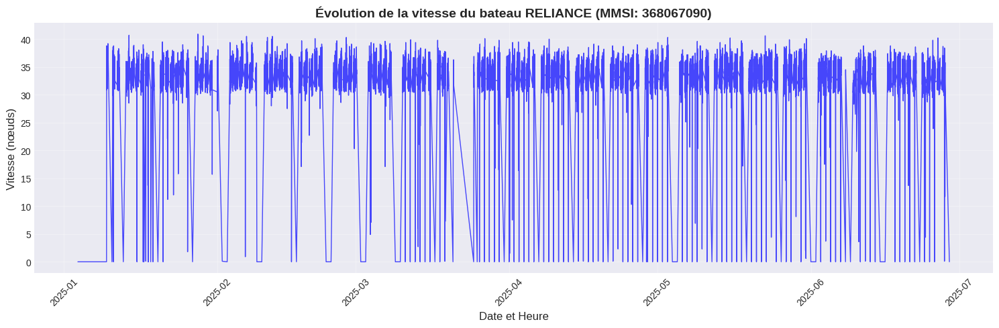

In [11]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df_trajectory['base_date_time'], df_trajectory['sog'], linewidth=1, color='blue', alpha=0.7)
ax.set_xlabel('Date et Heure', fontsize=12)
ax.set_ylabel('Vitesse (nœuds)', fontsize=12)
ax.set_title(f'Évolution de la vitesse du bateau {vessel_info["name"]} (MMSI: {vessel_info["mmsi"]})', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.2 Distribution de la vitesse

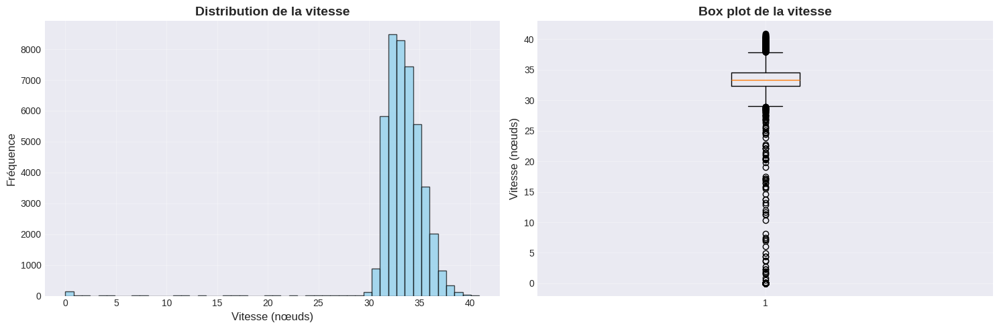

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Histogramme
ax1.hist(df_trajectory['sog'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
ax1.set_xlabel('Vitesse (nœuds)', fontsize=12)
ax1.set_ylabel('Fréquence', fontsize=12)
ax1.set_title('Distribution de la vitesse', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Box plot
ax2.boxplot(df_trajectory['sog'].dropna(), vert=True)
ax2.set_ylabel('Vitesse (nœuds)', fontsize=12)
ax2.set_title('Box plot de la vitesse', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 8.3 Évolution du cap (COG) dans le temps

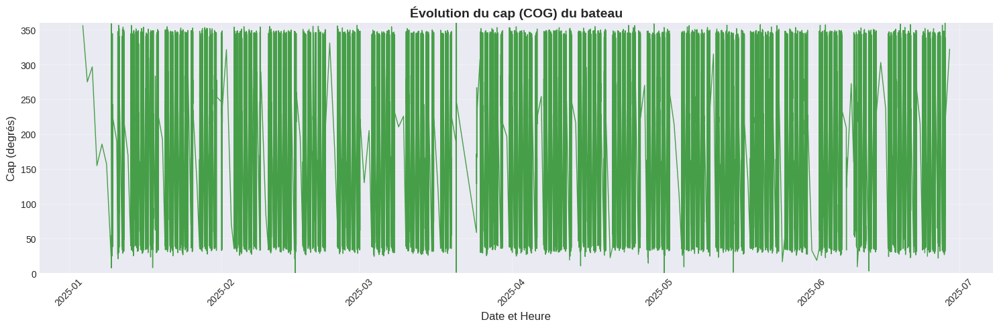

In [13]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df_trajectory['base_date_time'], df_trajectory['cog'], linewidth=1, color='green', alpha=0.7)
ax.set_xlabel('Date et Heure', fontsize=12)
ax.set_ylabel('Cap (degrés)', fontsize=12)
ax.set_title(f'Évolution du cap (COG) du bateau', fontsize=14, fontweight='bold')
ax.set_ylim(0, 360)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.4 Rose des vents (distribution du cap)

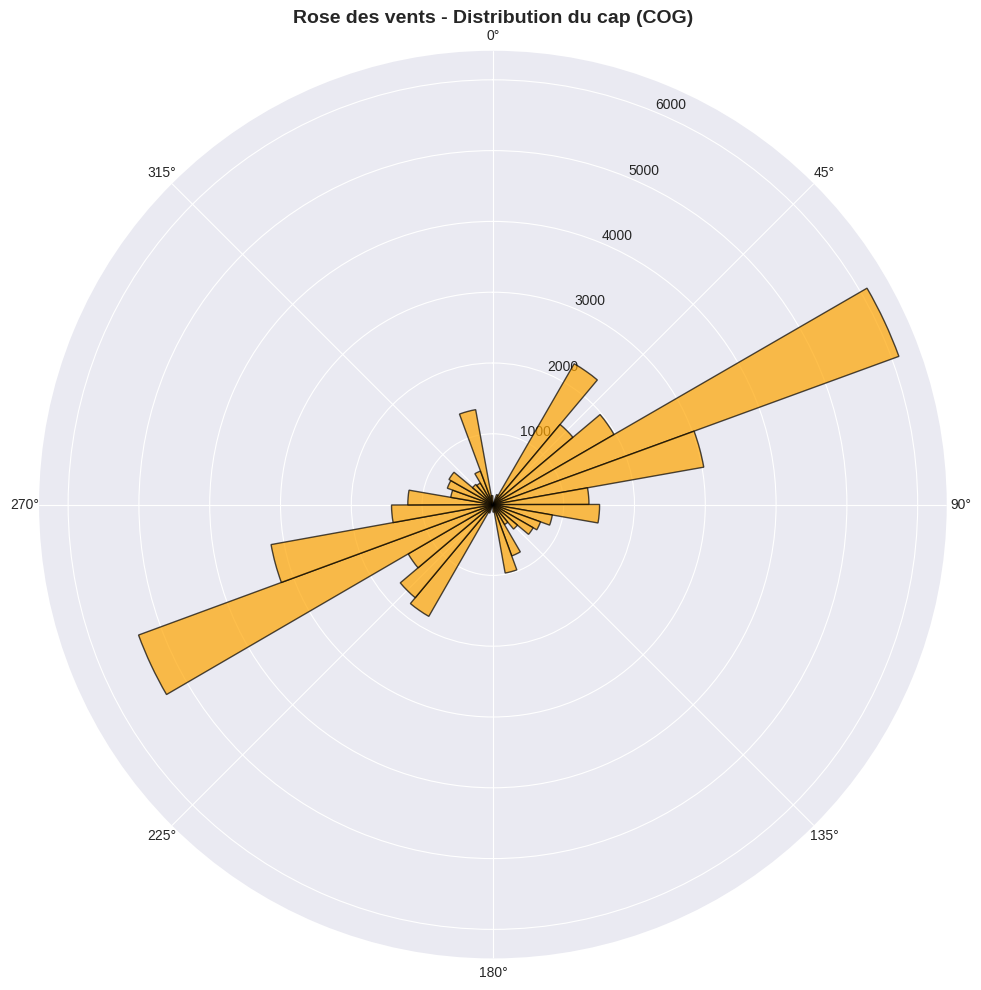

In [14]:
# Conversion des caps en radians pour la rose des vents
angles = np.deg2rad(df_trajectory['cog'].dropna())

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='polar')
ax.hist(angles, bins=36, color='orange', alpha=0.7, edgecolor='black')
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
ax.set_title('Rose des vents - Distribution du cap (COG)', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

### 8.5 Relation vitesse vs cap

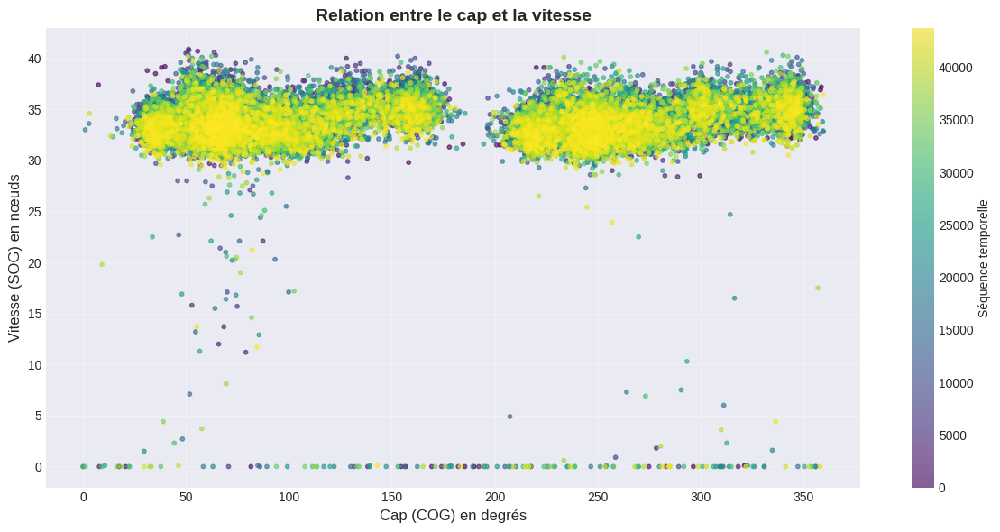

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))
scatter = ax.scatter(df_trajectory['cog'], df_trajectory['sog'], 
                     c=df_trajectory.index, cmap='viridis', alpha=0.6, s=10)
ax.set_xlabel('Cap (COG) en degrés', fontsize=12)
ax.set_ylabel('Vitesse (SOG) en nœuds', fontsize=12)
ax.set_title('Relation entre le cap et la vitesse', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Séquence temporelle', fontsize=10)
plt.tight_layout()
plt.show()

### 8.6 Distribution des statuts

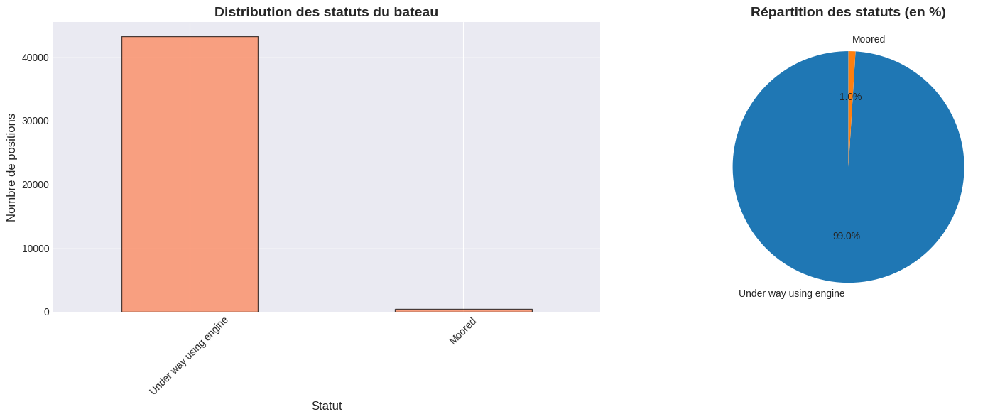

In [16]:
status_counts = df_trajectory['status_description'].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Graphique en barres
status_counts.plot(kind='bar', ax=ax1, color='coral', edgecolor='black', alpha=0.7)
ax1.set_xlabel('Statut', fontsize=12)
ax1.set_ylabel('Nombre de positions', fontsize=12)
ax1.set_title('Distribution des statuts du bateau', fontsize=14, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, alpha=0.3, axis='y')

# Camembert
ax2.pie(status_counts.values, labels=status_counts.index, autopct='%1.1f%%', startangle=90)
ax2.set_title('Répartition des statuts (en %)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## 9. Carte interactive de la trajectoire avec Folium

### 9.1 Carte simple avec trajectoire

In [11]:
# Calcul du centre de la carte
center_lat = df_trajectory['latitude'].mean()
center_lon = df_trajectory['longitude'].mean()

# Création de la carte
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=8,
    tiles='OpenStreetMap'
)

# Ajout de la trajectoire
coordinates = df_trajectory[['latitude', 'longitude']].values.tolist()
folium.PolyLine(
    coordinates,
    color='blue',
    weight=2,
    opacity=0.7,
    tooltip=f"Trajectoire de {vessel_info['name']}"
).add_to(m)

# Ajout du point de départ (vert)
first_pos = df_trajectory.iloc[0]
folium.Marker(
    location=[first_pos['latitude'], first_pos['longitude']],
    popup=f"<b>DÉPART</b><br>{first_pos['base_date_time']}<br>Vitesse: {first_pos['sog']:.1f} nœuds",
    icon=folium.Icon(color='green', icon='play', prefix='fa'),
    tooltip="Point de départ"
).add_to(m)

# Ajout du point d'arrivée (rouge)
last_pos = df_trajectory.iloc[-1]
folium.Marker(
    location=[last_pos['latitude'], last_pos['longitude']],
    popup=f"<b>ARRIVÉE</b><br>{last_pos['base_date_time']}<br>Vitesse: {last_pos['sog']:.1f} nœuds",
    icon=folium.Icon(color='red', icon='stop', prefix='fa'),
    tooltip="Point d'arrivée"
).add_to(m)

# Affichage de la carte
m

### 9.2 Carte avec trajectoire colorée selon la vitesse

In [10]:
# Création d'une nouvelle carte
m2 = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=8,
    tiles='OpenStreetMap'
)

# Normalisation de la vitesse pour la colormap
from matplotlib import cm
from matplotlib.colors import Normalize

norm = Normalize(vmin=df_trajectory['sog'].min(), vmax=df_trajectory['sog'].max())
colormap = cm.get_cmap('RdYlGn')

# Ajout de segments colorés selon la vitesse
for i in range(len(df_trajectory) - 1):
    start = df_trajectory.iloc[i]
    end = df_trajectory.iloc[i + 1]
    
    speed = start['sog']
    color_value = colormap(norm(speed))
    color_hex = '#{:02x}{:02x}{:02x}'.format(int(color_value[0]*255), int(color_value[1]*255), int(color_value[2]*255))
    
    folium.PolyLine(
        [(start['latitude'], start['longitude']), (end['latitude'], end['longitude'])],
        color=color_hex,
        weight=3,
        opacity=0.8
    ).add_to(m2)

# Marqueurs de départ et d'arrivée
folium.Marker(
    location=[first_pos['latitude'], first_pos['longitude']],
    popup=f"<b>DÉPART</b><br>{first_pos['base_date_time']}",
    icon=folium.Icon(color='green', icon='play', prefix='fa')
).add_to(m2)

folium.Marker(
    location=[last_pos['latitude'], last_pos['longitude']],
    popup=f"<b>ARRIVÉE</b><br>{last_pos['base_date_time']}",
    icon=folium.Icon(color='red', icon='stop', prefix='fa')
).add_to(m2)

# Note explicative
legend_html = '''
<div style="position: fixed; 
            bottom: 50px; right: 50px; width: 200px; height: 90px; 
            background-color: white; border:2px solid grey; z-index:9999; 
            font-size:14px; padding: 10px">
    <p><b>Légende - Vitesse</b></p>
    <p style="color: red;">● Rouge: Vitesse élevée</p>
    <p style="color: yellow;">● Jaune: Vitesse moyenne</p>
    <p style="color: green;">● Vert: Vitesse faible</p>
</div>
'''
m2.get_root().html.add_child(folium.Element(legend_html))

m2

### 9.3 Carte avec marqueurs pour chaque position

In [ ]:
# Création d'une carte avec des marqueurs pour chaque position, regroupés par mois
import calendar
df_trajectory['year_month'] = df_trajectory['base_date_time'].dt.to_period('M')
months = df_trajectory['year_month'].unique()
monthly_maps = {}
for month in months:
    df_month = df_trajectory[df_trajectory['year_month'] == month]
    if df_month.empty:
        continue
    center_lat = df_month['latitude'].mean()
    center_lon = df_month['longitude'].mean()
    m_month = folium.Map(location=[center_lat, center_lon], zoom_start=8, tiles='OpenStreetMap')
    coordinates = df_month[['latitude', 'longitude']].values.tolist()
    folium.PolyLine(coordinates, color='blue', weight=2, opacity=0.5).add_to(m_month)
    sample_size = min(100, len(df_month))
    df_sample = df_month.iloc[::max(1, len(df_month)//sample_size)]
    for idx, row in df_sample.iterrows():
        if 'anchor' in str(row['status_description']).lower():
            color = 'orange'
        elif 'moored' in str(row['status_description']).lower():
            color = 'purple'
        elif row['sog'] < 1:
            color = 'red'
        else:
            color = 'blue'
        popup_text = f"""<b>Position</b><br>Date/Heure: {row['base_date_time']}<br>Vitesse (SOG): {row['sog']:.1f} nœuds<br>Cap (COG): {row['cog']:.1f}°<br>Direction: {row['heading']:.0f}°<br>Statut: {row['status_description']}<br>Lat: {row['latitude']:.6f}<br>Lon: {row['longitude']:.6f}"""
        folium.CircleMarker(
            location=[row['latitude'], row['longitude']],
            radius=5,
            popup=folium.Popup(popup_text, max_width=300),
            color=color,
            fill=True,
            fillColor=color,
            fillOpacity=0.7
        ).add_to(m_month)
    # Ajout d'un titre pour le mois
    month_str = str(month)
    title_html = f'<h4 style="position:fixed; top:10px; left:10px; z-index:9999; background:white; padding:5px;">Trajectoire - {calendar.month_name[int(month_str[-2:])]} {month_str[:4]}</h4>'
    m_month.get_root().html.add_child(folium.Element(title_html))
    monthly_maps[month_str] = m_month
monthly_maps

NameError: name 'df_trajectory' is not defined

### 9.4 Carte avec animation temporelle

In [1]:
# Création d'une carte avec animation temporelle
m4 = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=8,
    tiles='OpenStreetMap'
)

# Préparation des données pour TimestampedGeoJson
features = []
for idx, row in df_trajectory.iterrows():
    feature = {
        'type': 'Feature',
        'geometry': {
            'type': 'Point',
            'coordinates': [row['longitude'], row['latitude']]
        },
        'properties': {
            'time': row['base_date_time'].isoformat(),
            'popup': f"Vitesse: {row['sog']:.1f} nœuds<br>Cap: {row['cog']:.1f}°",
            'icon': 'circle',
            'iconstyle': {
                'fillColor': 'blue',
                'fillOpacity': 0.8,
                'stroke': 'true',
                'radius': 5
            }
        }
    }
    features.append(feature)

# Ajout du plugin TimestampedGeoJson
plugins.TimestampedGeoJson(
    {'type': 'FeatureCollection', 'features': features},
    period='PT1M',  # Période entre chaque point
    add_last_point=True,
    auto_play=False,
    loop=False,
    max_speed=10,
    loop_button=True,
    date_options='YYYY-MM-DD HH:mm:ss',
    time_slider_drag_update=True
).add_to(m4)

# Ajout de la trajectoire complète en arrière-plan
folium.PolyLine(
    coordinates,
    color='lightblue',
    weight=2,
    opacity=0.3
).add_to(m4)

m4

NameError: name 'folium' is not defined

## 10. Sauvegarde des cartes

In [ ]:
# Sauvegarde des cartes en HTML
output_dir = '../data/generated'
import os
os.makedirs(output_dir, exist_ok=True)

vessel_name_clean = str(vessel_info['name']).replace(' ', '_').replace('/', '_')
vessel_mmsi = vessel_info['mmsi']

m.save(f'{output_dir}/trajectoire_{vessel_name_clean}_{vessel_mmsi}_simple.html')
m2.save(f'{output_dir}/trajectoire_{vessel_name_clean}_{vessel_mmsi}_vitesse.html')
m3.save(f'{output_dir}/trajectoire_{vessel_name_clean}_{vessel_mmsi}_marqueurs.html')
m4.save(f'{output_dir}/trajectoire_{vessel_name_clean}_{vessel_mmsi}_animation.html')

print("✓ Cartes sauvegardées dans le dossier:", output_dir)
print(f"  - trajectoire_{vessel_name_clean}_{vessel_mmsi}_simple.html")
print(f"  - trajectoire_{vessel_name_clean}_{vessel_mmsi}_vitesse.html")
print(f"  - trajectoire_{vessel_name_clean}_{vessel_mmsi}_marqueurs.html")
print(f"  - trajectoire_{vessel_name_clean}_{vessel_mmsi}_animation.html")

📁 Dossier actuel: /home/yani/master1/PROJET/ais/notebooks


## 11. Export des données de trajectoire

In [ ]:
# Export en CSV
csv_filename = f'{output_dir}/trajectoire_{vessel_name_clean}_{vessel_mmsi}.csv'
df_trajectory.to_csv(csv_filename, index=False)
print(f"✓ Données exportées en CSV: {csv_filename}")

# Export en Excel
excel_filename = f'{output_dir}/trajectoire_{vessel_name_clean}_{vessel_mmsi}.xlsx'
with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    df_trajectory.to_excel(writer, sheet_name='Positions', index=False)
    
    # Ajout d'une feuille avec les statistiques
    stats_df = pd.DataFrame({
        'Métrique': [
            'MMSI', 'Nom du bateau', 'Type', 'Nombre de positions',
            'Première position', 'Dernière position', 'Durée totale',
            'Vitesse moyenne (nœuds)', 'Vitesse max (nœuds)', 'Vitesse min (nœuds)',
            'Cap moyen (°)', 'Latitude min', 'Latitude max',
            'Longitude min', 'Longitude max'
        ],
        'Valeur': [
            vessel_info['mmsi'], vessel_info['name'], vessel_info['vessel_type'],
            len(df_trajectory), df_trajectory['base_date_time'].min(),
            df_trajectory['base_date_time'].max(), str(duree),
            f"{df_trajectory['sog'].mean():.2f}",
            f"{df_trajectory['sog'].max():.2f}",
            f"{df_trajectory['sog'].min():.2f}",
            f"{df_trajectory['cog'].mean():.2f}",
            f"{df_trajectory['latitude'].min():.6f}",
            f"{df_trajectory['latitude'].max():.6f}",
            f"{df_trajectory['longitude'].min():.6f}",
            f"{df_trajectory['longitude'].max():.6f}"
        ]
    })
    stats_df.to_excel(writer, sheet_name='Statistiques', index=False)

print(f"✓ Données exportées en Excel: {excel_filename}")

## 12. Résumé final

In [ ]:
print("="*70)
print("RÉSUMÉ DE L'ANALYSE DE TRAJECTOIRE")
print("="*70)
print(f"\nBateau analysé: {vessel_info['name']} (MMSI: {vessel_info['mmsi']})")
print(f"Type: {vessel_info['vessel_type']}")
print(f"\nNombre total de positions: {len(df_trajectory)}")
print(f"Période: {df_trajectory['base_date_time'].min()} → {df_trajectory['base_date_time'].max()}")
print(f"Durée: {duree}")
print(f"\nVitesse moyenne: {df_trajectory['sog'].mean():.2f} nœuds")
print(f"Cap moyen: {df_trajectory['cog'].mean():.2f}°")
print(f"\nZone géographique:")
print(f"  Latitude: {df_trajectory['latitude'].min():.4f}° → {df_trajectory['latitude'].max():.4f}°")
print(f"  Longitude: {df_trajectory['longitude'].min():.4f}° → {df_trajectory['longitude'].max():.4f}°")
print(f"\nStatut principal: {df_trajectory['status_description'].mode()[0]}")
print(f"\nFichiers générés:")
print(f"  - 4 cartes interactives HTML")
print(f"  - 1 fichier CSV avec toutes les données")
print(f"  - 1 fichier Excel avec données et statistiques")
print(f"\nLocalisation des fichiers: {output_dir}")
print("="*70)